<a id="chapter-06"></a>

# Chapter 06 · Deep Q-Networks / 深度 Q 网络

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 从 Q-learning 过渡到函数逼近
- 理解 replay buffer 与 target network
- 写出正确的 TD target 和 loss

**开始前最好已经会：**

- 理解第 5 章 Bellman 最优方程
- 掌握 PyTorch 的前向/损失/反向
- 理解 epsilon-greedy


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Real-life value iteration | 从模型到采样的过渡 | 详细 |
| Tabular Q-learning | TD 更新与 chain 实验 | 详细 |
| Deep Q-learning | loss、replay、target network 推导 | 详细 |
| DQN on Pong: wrappers/model/training/performance/play | 完整流程与真实源码路线 | 详细 |
| Things to try | 练习与扩展 | 实践 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

现实环境没有转移概率表，而且状态可能是图像。怎样用实际经历替代模型，用神经网络替代表格？

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

DQN 用神经网络一次输出所有动作的 Q 值。经验回放削弱样本相关性；目标网络让训练目标短期稳定。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $Q_\theta(s,a)$ | online network 的预测 | 当前正在更新 |
| $Q_{\theta^-}$ | target network | 短时间保持不变 |
| $\delta$ | TD error | 目标减预测 |
| $\mathcal D$ | replay buffer | 保存 transition |
| $d$ | 终止标志 | 真正终止时为 1 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 从 Bellman 方程到采样更新

Bellman 最优方程中的期望需要知道 $P$。未知模型时，用一次真实 transition $(s,a,r,s')$ 作为随机样本：

$$y=r+\gamma(1-d)\max_{a'}Q(s',a')$$

预测与目标之差为

$$\delta=y-Q(s,a)$$

表格 Q-learning 更新 $Q\leftarrow Q+\alpha\delta$。

### 2. 把表格换成神经网络

网络无法只修改一个格子，因此把 TD error 变成回归损失：

$$L(\theta)=\mathbb E_{(s,a,r,s')\sim\mathcal D}\left[\ell(Q_\theta(s,a),y)\right]$$

其中 $\ell$ 可用 MSE 或 Huber loss。

### 3. 为什么需要 target network

若 $y$ 也由同一个快速变化的网络产生，就像一边追逐一边移动的目标。DQN 用延迟参数 $\theta^-$ 计算

$$y=r+\gamma(1-d)\max_{a'}Q_{\theta^-}(s',a')$$

并在计算 target 时停止梯度。这是 semi-gradient：只对左侧预测求导。

### 4. replay buffer 解决什么

连续帧高度相关，而且只反映最近策略。随机抽取旧 transition 能打散时间相关性并复用样本，但也使数据变成 off-policy；Q-learning 的目标形式允许这种复用。


## 4. 手算一个最小例子


假设 $r=1,\gamma=0.9,d=0$，target network 在下一状态输出 `[2,3]`，当前 $Q(s,a)=2.5$：

$$y=1+0.9\times3=3.7,\qquad \delta=3.7-2.5=1.2$$

若该 transition 终止，$y=1$，不能再加下一状态价值。先手算这个例子，再去读实际 batch 代码。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### Q-learning 与 DQN

表格更新：
$$Q(s,a)\leftarrow Q(s,a)+\alpha\left[r+\gamma\max_{a'}Q(s',a')-Q(s,a)\right]$$

DQN 目标与损失：
$$y=r+\gamma(1-d)\max_{a'}Q_{\theta^-}(s',a'),\qquad L(\theta)=\mathbb E[(Q_\theta(s,a)-y)^2]$$

$\theta^-$ 是延迟同步的 target network；计算 $y$ 时必须停止梯度。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $Q_\theta(s,\cdot)$ | `net(states)`，shape `(B, A)` | 每个状态的所有动作价值 |
| $Q_\theta(s,a)$ | `.gather(1, actions[:, None])` | 只取实际动作列 |
| $\max_{a'}Q_{\theta^-}(s',a')$ | `target_net(next_states).max(1).values` | 下一状态贪心价值 |
| $1-d$ | `~terminated` | 终止样本不 bootstrap |
| $y$ | `rewards + gamma * mask * next_q` | 必须停止梯度 |
| $L$ | `smooth_l1_loss(q_sa, target)` | 对 batch 平均的 TD loss |

**从公式过渡到代码时：**小型 chain 环境让 Q-learning 的核心更新一目了然；完整 Pong DQN 请沿下方链接阅读。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import numpy as np

rng = np.random.default_rng(42)
Q = np.zeros((5, 2))  # 动作 0=左，1=右；状态 4 为终点
alpha, gamma, epsilon = 0.2, 0.95, 0.2

for episode in range(1500):
    s = 0
    for _ in range(20):
        a = rng.integers(2) if rng.random() < epsilon else int(Q[s].argmax())
        s_next = max(0, s - 1) if a == 0 else min(4, s + 1)
        r = 1.0 if s_next == 4 else 0.0
        terminated = s_next == 4
        target = r if terminated else r + gamma * Q[s_next].max()
        Q[s, a] += alpha * (target - Q[s, a])
        s = s_next
        if terminated:
            break

print(np.round(Q, 3))
print("greedy policy:", Q.argmax(axis=1))


[[0.815 0.857]
 [0.815 0.902]
 [0.857 0.95 ]
 [0.902 1.   ]
 [0.    0.   ]]
greedy policy: [1 1 1 1 0]


### 怎样读运行结果

当前 notebook 先用表格 chain 验证采样更新。输出策略应在非终止状态选择右移。随后阅读项目 DQN 脚本时，按上表逐行寻找 network、gather、target、mask 与 loss。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
初始化 online Qθ、target Qθ-、replay D
for frame in 1..N:
    以 epsilon-greedy 从 Qθ(obs) 选 action
    与环境交互，存 transition 到 D
    若 D 尚未 warm up：continue
    batch = D.sample(B)
    predicted = Qθ(states).gather(actions)
    with no_grad:
next = max_a Qθ-(next_states, a)
target = rewards + γ * non_terminal * next
    loss = Huber(predicted, target)
    backward + optimizer.step
    每 K 帧同步 θ- ← θ；逐步降低 epsilon
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import torch
import torch.nn.functional as F

# 一个完整的 batch DQN loss，显式展示 shape。
q_all = torch.tensor([[1., 2.], [3., 1.]], requires_grad=True)   # (B=2, A=2)
actions = torch.tensor([1, 0])                                  # (B,)
rewards = torch.tensor([1., -1.])
terminated = torch.tensor([False, True])
target_next_all = torch.tensor([[4., 2.], [5., 6.]])
q_sa = q_all.gather(1, actions[:, None]).squeeze(1)
with torch.no_grad():
    target = rewards + 0.9 * (~terminated) * target_next_all.max(1).values
loss = F.smooth_l1_loss(q_sa, target)
loss.backward()
print("q_sa:", q_sa.detach(), "target:", target, "loss:", loss.item())
assert q_sa.shape == target.shape == (2,)


q_sa: tensor([2., 3.]) target: tensor([ 4.6000, -1.0000]) loss: 2.799999952316284


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`wrappers.py`](../../Chapter06/lib/wrappers.py) | `ImageToPyTorch`, `BufferWrapper`, `make_env` | 像素预处理、帧堆叠与环境创建 |
| [`dqn_model.py`](../../Chapter06/lib/dqn_model.py) | `DQN.forward` | 卷积输出尺寸与动作 Q |
| [`02_dqn_pong.py`](../../Chapter06/02_dqn_pong.py) | `ExperienceBuffer`, `Agent.play_step`, `batch_to_tensors`, `calc_loss` | 完整训练数据流 |
| [`03_dqn_play.py`](../../Chapter06/03_dqn_play.py) | 评估循环 | 加载模型、贪心动作与渲染 |

<details>
<summary>为什么按这个顺序读</summary>

精读顺序不要从 `main` 开始：先确认 wrapper 输出 shape/dtype，再算 `DQN` 卷积后的展平维度，然后跟踪 `Agent.play_step` 如何产生 terminal transition，最后进入 `calc_loss`。在 loss 中逐项核对 `gather`、terminal mask、target network 和 `no_grad`；这四处决定数学是否正确。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**Q-learning 在链式环境中的 episode return

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


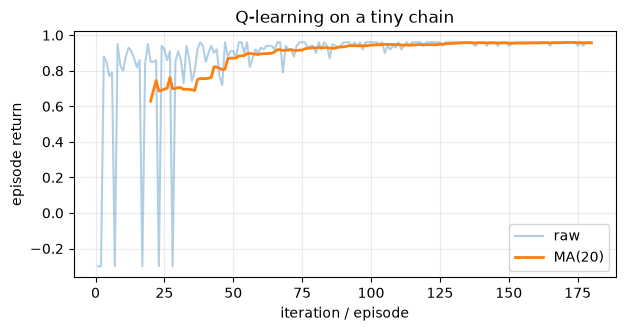

greedy actions: [1 1 1 1 1 0] last-20 mean: 0.9570000000000002


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(6)
q = np.zeros((6, 2))
returns = []
for episode in range(180):
    s, total = 0, 0.0
    epsilon = max(0.05, 1.0 - episode / 140)
    for _ in range(30):
        a = rng.integers(2) if rng.random() < epsilon else np.argmax(q[s])
        ns = max(0, s - 1) if a == 0 else min(5, s + 1)
        reward, done = (1.0 if ns == 5 else -0.01), ns == 5
        target = reward if done else reward + 0.95 * q[ns].max()
        q[s, a] += 0.2 * (target - q[s, a])
        total += reward; s = ns
        if done: break
    returns.append(total)

plot_curve(returns, "Q-learning on a tiny chain", "episode return", window=20)
print("greedy actions:", q.argmax(axis=1), "last-20 mean:", np.mean(returns[-20:]))


### 曲线怎么读

原始回报噪声很大，移动平均应逐渐上升并稳定；同时 greedy action 应在非终止状态选择向右。只看 loss 下降不能证明策略变好。

### 调参过程：一次只改变一个因素

- 固定 replay、target、网络结构，先让 epsilon 从 1 线性下降。
- 若回报不升，依次检查终止 mask、target、学习率，再动网络。
- 基线稳定后才分别调整 replay warm-up、batch size、target sync。

### 失败案例复盘

- 终止 transition 仍加入 bootstrap，Q 值系统性偏高。
- epsilon 降得太快，buffer 中几乎只有早期坏策略数据。
- 训练回报上升但评估仍使用 epsilon，误判模型性能。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 只对实际执行的动作使用 `gather` 取 $Q(s,a)$。
- target 应位于 `torch.no_grad()` 中或显式 `.detach()`。
- 先填充一段 replay buffer 再训练；否则初期样本高度相似。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把 epsilon 设为 0，解释全零 Q 表的 `argmax` 为什么可能导致永远学不到终点。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

epsilon=0 且全零 Q 时，NumPy `argmax` 总返回第一个动作；chain 示例的动作 0 向左，agent 会一直停在起点，永远看不到终点奖励。可用随机 tie-breaking、非零 epsilon 或 optimistic initialization 解决。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- Q-learning 是 Bellman 最优方程的采样近似。
- DQN 用网络替代表格，用回归 loss 替代单格更新。
- replay buffer 打散相关性并复用经验。
- target network 与停止梯度让目标更稳定。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么 target 要停止梯度？为什么 `gather` 只取执行动作，而不是对当前 Q 也取 max？

<details>
<summary>展开答案</summary>

target 是监督信号，DQN 的 semi-gradient 不沿 target 分支更新。行为数据告诉我们实际执行的是哪个动作，因此只应回归该动作的 Q；对当前 Q 取 max 会训练错误的动作。
</details>


## 17. 与前后章节连接

第 7 章把这里的 selector、agent、experience、buffer、target net 拆成复用组件；第 8 章逐项修正基础 DQN 的弱点。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

Huber loss 比 MSE 对异常 TD error 更稳健；soft target update 使用 $\theta^-\leftarrow\tau\theta+(1-\tau)\theta^-$。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-06) · [← 学习索引](../README.md)
